In [19]:
import pandas as pd
import matplotlib.pyplot as plt

cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
df = pd.read_csv("../data/train_FD001.txt", sep = r"\s", header = None, names = cols)



C:\Users\bryan\AppData\Local\Temp\ipykernel_36568\3098226808.py:5: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv("../data/train_FD001.txt", sep = r"\s", header = None, names = cols)


In [20]:
df.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [21]:
stds = df.drop(columns = ["unit", "cycle"]).std().sort_values()
print(stds)

s1     0.000000e+00
op3    0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
op2    2.930621e-04
s6     1.388985e-03
op1    2.187313e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64


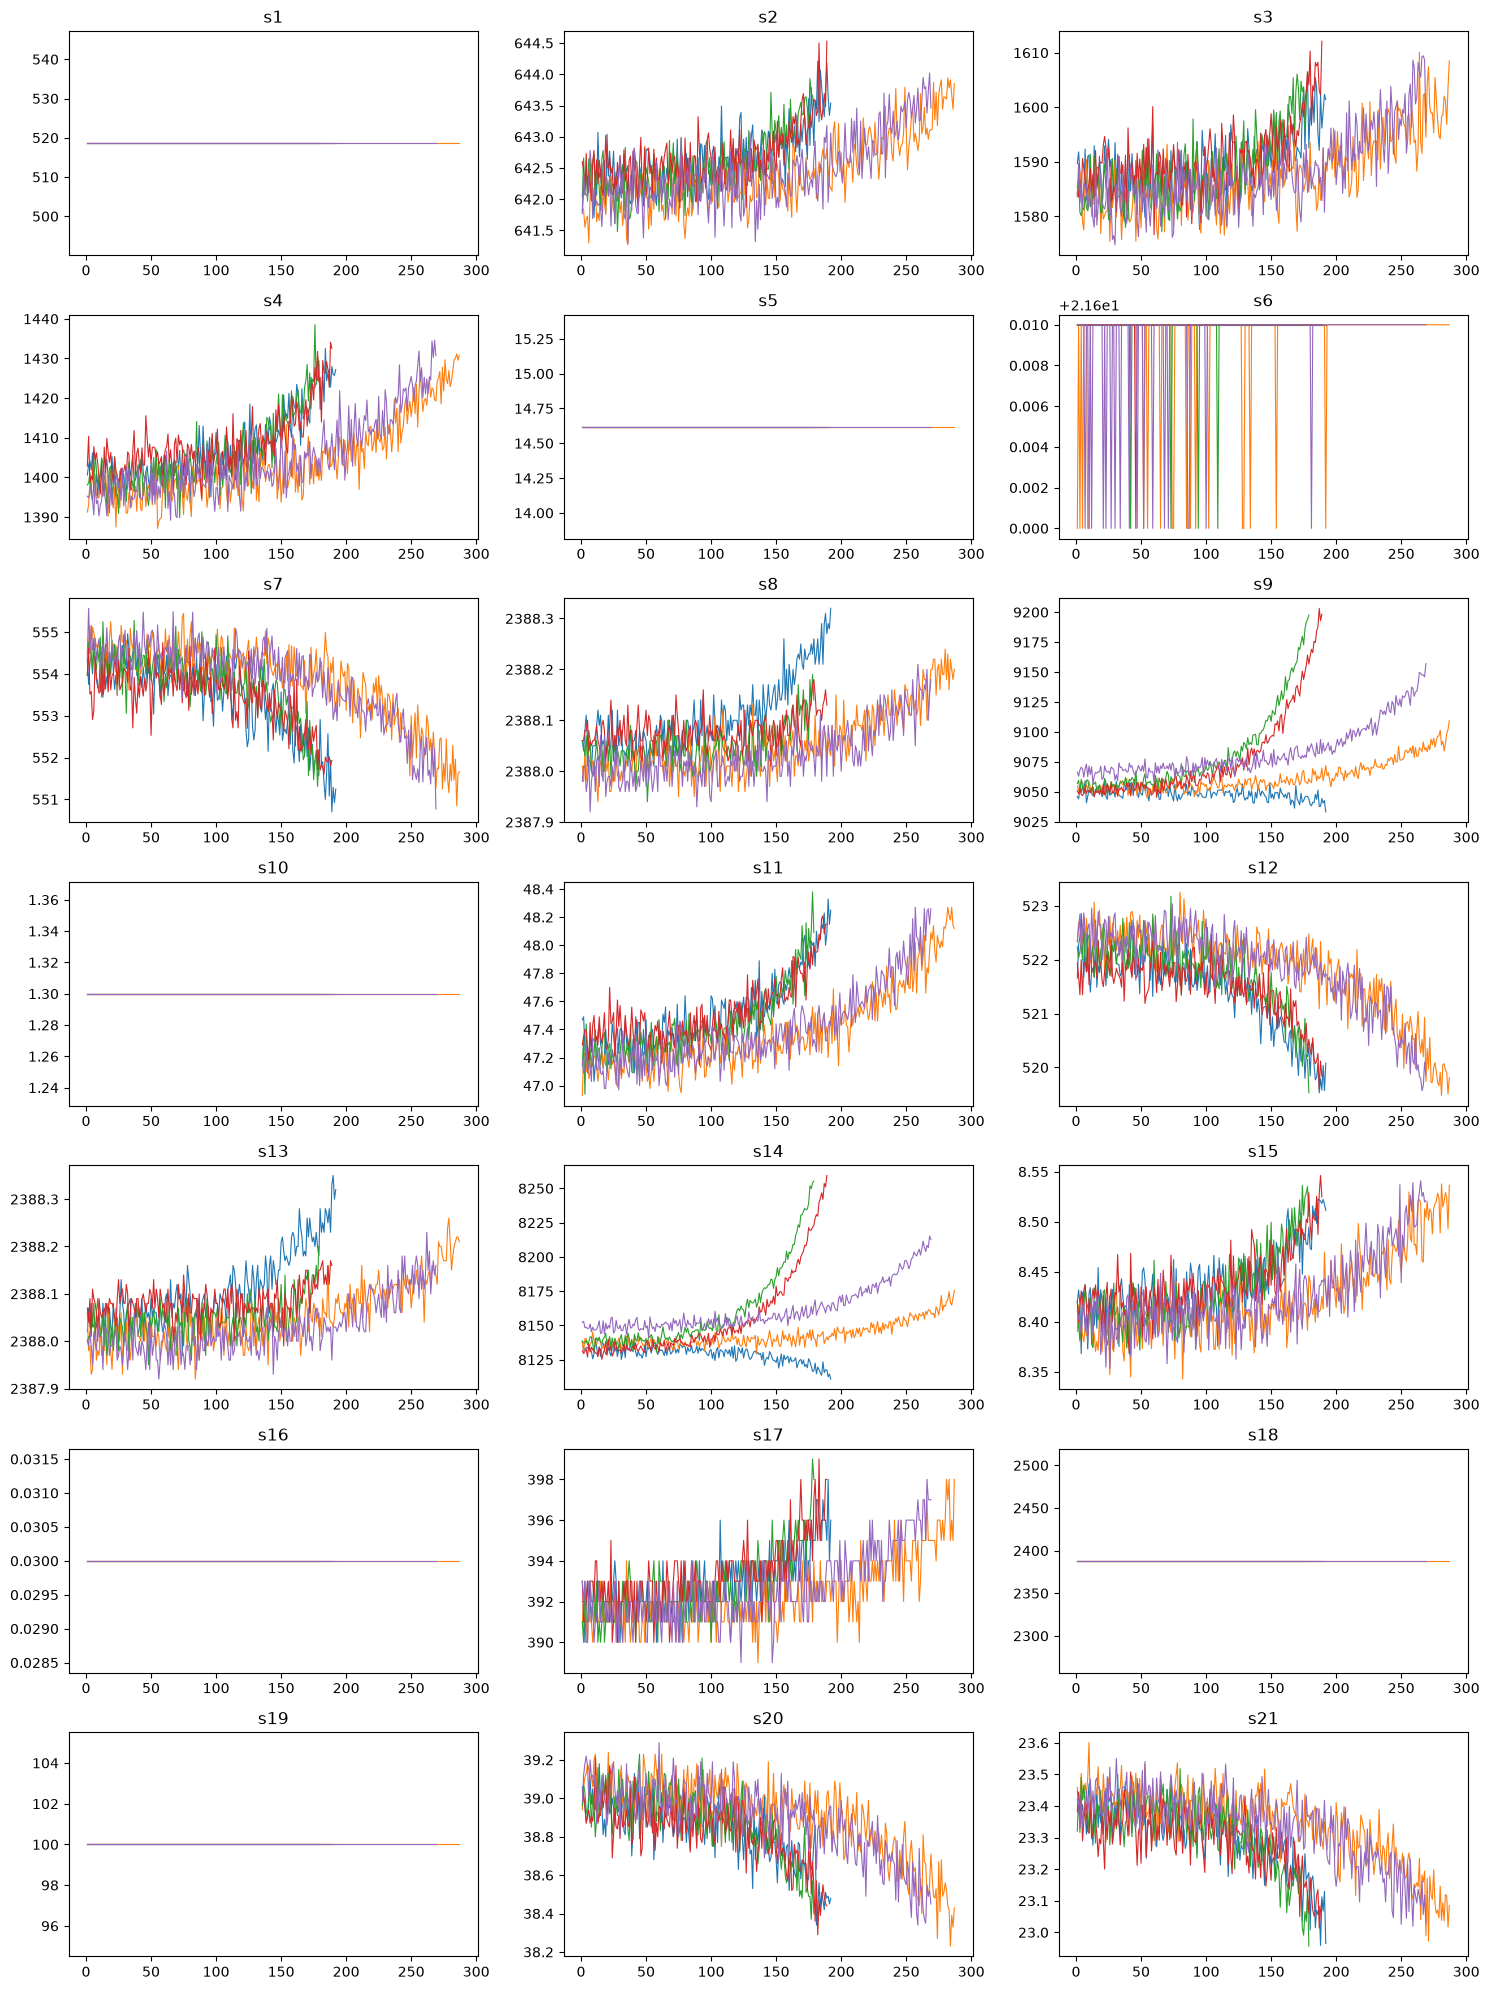

In [22]:
s = [f"s{i}" for i in range (1, 22)]
fig, axes = plt.subplots(7, 3, figsize = (15,20))

for ax, s in zip(axes.flat, s):
    units = [1, 2, 3, 4, 5]
    for unit in units:
        e = df[df["unit"] == unit]
        ax.plot(e["cycle"], e[s], linewidth = 0.8)
    ax.set_title(s)
plt.tight_layout()
plt.show()
    

s1, s5, s10, s16, s18, s19 are straight lines which tells us 0 information.
s6 dropped as well because it looks like noise. 

In [23]:
drop_cols = ["op1", "op2", "op3", "s1", "s6", "s5", "s10", "s16", "s18", "s19"]
df = df.drop(columns = drop_cols)
print(df.columns.tolist())

['unit', 'cycle', 's2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [24]:
max_cycle = df.groupby("unit")["cycle"].transform("max")
df["RUL"] = max_cycle - df["cycle"]

In [25]:
df["RUL"] = df["RUL"].clip(upper=125)
print("max RUL:", df["RUL"].max())

max RUL: 125


In [26]:
print(df[df["unit"] == 1][["unit", "cycle", "RUL"]].head())

   unit  cycle  RUL
0     1      1  125
1     1      2  125
2     1      3  125
3     1      4  125
4     1      5  125


In [27]:
from sklearn.preprocessing import MinMaxScaler
sensor_cols = [c for c in df.columns if c.startswith("s")]

scaler = MinMaxScaler()
df[sensor_cols] = scaler.fit_transform(df[sensor_cols])

print(df[sensor_cols].describe().loc[["min", "max"]])



      s2   s3   s4   s7   s8   s9  s11  s12  s13  s14  s15  s17  s20  s21
min  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
max  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0


In [28]:
import numpy as np

WINDOW = 30

def make_windows(df, window):
    X, y = [], []
    for unit, e in df.groupby("unit"):
        data = e[sensor_cols].values
        rul = e["RUL"].values
        for i in range(len(e) - window + 1):
            X.append(data[i : i + window])
            y.append(rul[i + window - 1])
    return np.array(X), np.array(y)

The code above is making windows.
30 cycles - 1 result because our information lives in the trend overtime.

In index
rows = sensor data from rows 0 - 29 (multiple columns), target = RUL at row 29
rows = sensor data from rows 1 - 30 (multiple columns), target = RUL at row 30

Next is train/validation split.



In [29]:
rng = np.random.default_rng(42)

units = df["unit"].unique()
val_units = rng.choice(units, size = 20, replace = False)

train_df = df[~df["unit"].isin(val_units)]
val_df = df[df["unit"].isin(val_units)]

X_train, y_train = make_windows(train_df, WINDOW)
X_val, y_val = make_windows(val_df, WINDOW)

print("val engines: ", sorted(val_units))
print("train: ", X_train.shape, y_train.shape)
print("val: ", X_val.shape, y_val.shape)

val engines:  [np.int64(8), np.int64(9), np.int64(13), np.int64(18), np.int64(37), np.int64(46), np.int64(48), np.int64(50), np.int64(55), np.int64(62), np.int64(64), np.int64(69), np.int64(72), np.int64(74), np.int64(76), np.int64(84), np.int64(85), np.int64(87), np.int64(90), np.int64(95)]
train:  (14070, 30, 14) (14070,)
val:  (3661, 30, 14) (3661,)


In [30]:
import torch
import torch.nn as nn

class CNN1D(nn.Module):
    def __init__(self, n_features = 14):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_features, 32, kernel_size = 5, padding = 2),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size = 5, padding = 2),
            nn.ReLU(),
        )
        self.head = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1),
        )
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.conv(x)
        x = x.mean(dim=2)
        x = self.head(x)
        return x.squeeze(-1)

model = CNN1D()
print(model)
print("params: ", sum(p.numel() for p in model.parameters()))

CNN1D(
  (conv): Sequential(
    (0): Conv1d(14, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (3): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
params:  16801


In [31]:
fake = torch.randn(8, 30, 14)
print(model(fake).shape)

torch.Size([8])


In [32]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(torch.tensor(X_train, dtype = torch.float32),
                         torch.tensor(y_train, dtype = torch.float32))
val_ds = TensorDataset(torch.tensor(X_val, dtype = torch.float32),
                       torch.tensor(y_val, dtype = torch.float32))

train_loader = DataLoader(train_ds, batch_size = 64, shuffle = True)
val_loader = DataLoader(val_ds, batch_size = 256)

In [33]:
from tqdm import tqdm

def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    for windows, ruls in tqdm(loader, desc = "Training", leave = False):
        windows, ruls = windows.to(device), ruls.to(device)
        output = model(windows)
        loss = loss_fn(output, ruls)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(windows)
    return (total_loss / len(loader.dataset)) ** 0.5 #RMSE

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for windows, ruls in loader:
            windows, ruls = windows.to(device), ruls.to(device)
            output = model(windows)
            total_loss += loss_fn(output, ruls).item() * len(windows)
    return (total_loss / len(loader.dataset)) ** 0.5

In [35]:
device = "cuda"
model = CNN1D().to(device)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

EPOCHS = 30

best_val = float("inf")

for epoch in range(EPOCHS):
    train_rmse = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_rmse = evaluate(model, val_loader, loss_fn)

    if val_rmse < best_val:
        best_val = val_rmse
    print(f"epoch {epoch + 1:2d} | train RMSE {train_rmse:6.2f} | val RMSE {val_rmse:6.2f}")
print("best val RMSE: ", round(best_val, 2))

epoch  1 | train RMSE  53.21 | val RMSE  26.51


epoch  2 | train RMSE  26.12 | val RMSE  22.57


epoch  3 | train RMSE  24.98 | val RMSE  22.47


epoch  4 | train RMSE  24.56 | val RMSE  22.12


epoch  5 | train RMSE  24.27 | val RMSE  22.27


...

epoch 26 | train RMSE  21.32 | val RMSE  19.98


epoch 27 | train RMSE  21.07 | val RMSE  19.44


epoch 28 | train RMSE  20.83 | val RMSE  19.06


epoch 29 | train RMSE  20.65 | val RMSE  18.45


epoch 30 | train RMSE  20.49 | val RMSE  18.42
best val RMSE:  18.42


In [37]:
EPOCHS = 200

for epoch in range(EPOCHS):
    train_rmse = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_rmse = evaluate(model, val_loader, loss_fn)

    if val_rmse < best_val:
        best_val = val_rmse
        torch.save(model.state_dict(), "../models/cnn1d_best.pth")

    print(f"epoch {epoch + 1:2d} | train RMSE {train_rmse:6.2f} | val RMSE {val_rmse:6.2f}")
print("best val RMSE: ", round(best_val, 2))

epoch  1 | train RMSE  19.85 | val RMSE  17.97


epoch  2 | train RMSE  19.90 | val RMSE  18.20


epoch  3 | train RMSE  19.68 | val RMSE  17.74


epoch  4 | train RMSE  19.60 | val RMSE  17.41


epoch  5 | train RMSE  19.25 | val RMSE  17.15


...

epoch 196 | train RMSE  15.06 | val RMSE  14.99


epoch 197 | train RMSE  15.09 | val RMSE  14.64


epoch 198 | train RMSE  15.09 | val RMSE  15.34


epoch 199 | train RMSE  15.18 | val RMSE  15.13


epoch 200 | train RMSE  15.08 | val RMSE  15.24
best val RMSE:  14.64
